# Quy trình huấn luyện và tối ưu hóa mô hình phân loại khuyết tật bề mặt thép bằng ONNX

## Mục tiêu thực nghiệm
Xây dựng trọn vẹn quy trình từ huấn luyện đến tối ưu hóa suy luận trên CPU cho bài toán **kiểm tra ngoại quan bề mặt thép (NEU Surface Defect — 6 lớp lỗi, 1.800 ảnh)**:
1. **Xử lý dữ liệu và học chuyển giao:** Chia dữ liệu theo tỷ lệ phân tầng (Stratified Split 70/15/15) nhằm tránh rò rỉ dữ liệu và tinh chỉnh mô hình `MobileNetV2`.
2. **Đánh giá kiểm tra ngoại quan (AOI):** Đo độ chính xác tổng thể, Precision/Recall từng lớp và vẽ ma trận nhầm lẫn trên tập kiểm thử độc lập.
3. **Xuất ONNX và phẫu thuật đồ thị:** Kiểm chứng công thức toán học của BatchNorm Folding bằng NumPy, xuất file ONNX và tối ưu hóa đồ thị bằng `onnx-simplifier`.
4. **Kiểm định sai số và đo hiệu năng:** Chứng minh sai số dấu phẩy động nhỏ hơn $10^{-5}$ và đo độ trễ thực tế (Mean, P50, P95, P99) trên CPU.

## 1. Thiết lập môi trường và tính tái lập
- Cố định `SEED = 42` cho Python, NumPy và PyTorch để đảm bảo kết quả chia tập dữ liệu và khởi tạo trọng số nhất quán giữa các lần chạy.
- Các đường dẫn lưu trữ (`models/`, `assets/`, `data/`) được ánh xạ tương đối từ thư mục gốc của dự án.

In [14]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# Đảm bảo đường dẫn luôn tính từ gốc dự án (vì notebook nằm trong thư mục notebooks/)
PROJECT_ROOT = Path("..").resolve()
DATA_ROOT    = PROJECT_ROOT / "data" / "NEU-DET"
MODELS_DIR   = PROJECT_ROOT / "models"
ASSETS_DIR   = PROJECT_ROOT / "assets"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project Root: {PROJECT_ROOT}")
print(f"Device:       {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Project Root: /home/nvbao/Projects/industrial-defect
Device:       cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 2. Xử lý dữ liệu công nghiệp (NEU Surface Defect)
Các quyết định kỹ thuật chính:
- **Tránh rò rỉ dữ liệu (data leakage):** Gom toàn bộ 1.800 ảnh (300 ảnh/lớp × 6 lớp) rồi chia phân tầng cố định theo tỷ lệ `70% Train (1.260) / 15% Val (270) / 15% Test (270)`. Tập Test được tách biệt hoàn toàn trong suốt quá trình huấn luyện để đánh giá khách quan và làm chuẩn kiểm định sau khi chuyển sang ONNX.
- **Chuyển ảnh xám sang RGB:** Ảnh gốc của bộ NEU là ảnh xám kích thước `200×200`. Ta chuyển sang 3 kênh màu bằng `.convert("RGB")` để tận dụng trọn vẹn trọng số pretrained ImageNet của `MobileNetV2`.
- **Tăng cường dữ liệu an toàn cho bài toán ngoại quan:** Áp dụng lật ngang/dọc (`RandomHorizontalFlip`, `RandomVerticalFlip`), xoay nhẹ (`±15°`) và điều chỉnh độ sáng/tương phản nhẹ (`ColorJitter`), tránh cắt xén mạnh làm mất các vết xước mảnh ở rìa ảnh.

In [2]:
CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches",
]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# 1. Gom toàn bộ 1.800 ảnh từ train/images và validation/images
all_samples = []
for split_dir in ["train", "validation"]:
    img_root = DATA_ROOT / split_dir / "images"
    for cls_name in CLASS_NAMES:
        cls_dir = img_root / cls_name
        for f in sorted(cls_dir.iterdir()):
            if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}:
                all_samples.append((str(f), CLASS_TO_IDX[cls_name]))
labels = [lbl for _, lbl in all_samples]

In [3]:
# 2. Chia Stratified Split cố định (70% Train / 15% Val / 15% Test)
train_samples, temp_samples, _, temp_labels = train_test_split(
    all_samples, labels, test_size=0.30, stratify=labels, random_state=SEED
)
val_samples, test_samples = train_test_split(
    temp_samples, test_size=0.50, stratify=temp_labels, random_state=SEED
)
print(f"Tổng ảnh: {len(all_samples)} -> Train: {len(train_samples)} | Val: {len(val_samples)} | Test: {len(test_samples)}")

Tổng ảnh: 1800 -> Train: 1260 | Val: 270 | Test: 270


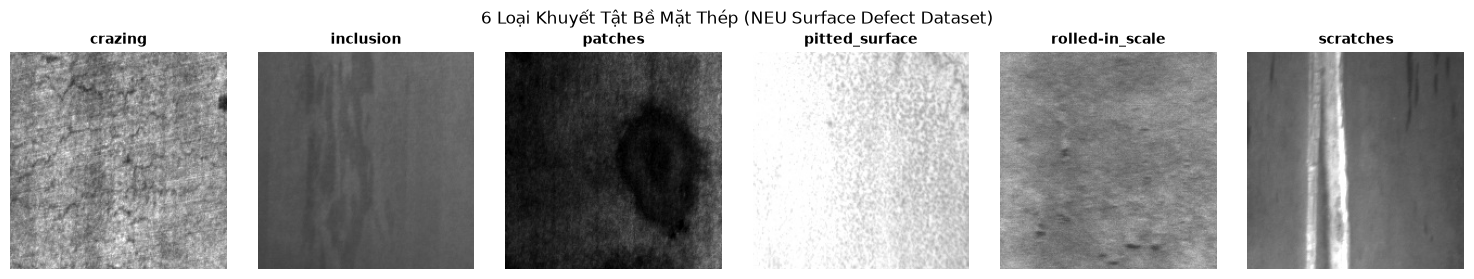

In [4]:
# 3. Trực quan hóa 1 ảnh mẫu của mỗi lớp lỗi
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
for idx, cls_name in enumerate(CLASS_NAMES):
    sample_path = next(p for p, l in train_samples if l == idx)
    img = Image.open(sample_path)
    axes[idx].imshow(img, cmap="gray")
    axes[idx].set_title(cls_name, fontsize=10, fontweight="bold")
    axes[idx].axis("off")
plt.suptitle("6 Loại Khuyết Tật Bề Mặt Thép (NEU Surface Defect Dataset)", fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
class NEUDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")  # Chuyển ảnh xám -> 3 kênh RGB cho MobileNetV2
        if self.transform:
            img = self.transform(img)
        return img, label
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
train_loader = DataLoader(NEUDataset(train_samples, train_tf), batch_size=32, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(NEUDataset(val_samples,   eval_tf),  batch_size=32, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(NEUDataset(test_samples,  eval_tf),  batch_size=32, shuffle=False, num_workers=4, pin_memory=True)

## 3. Huấn luyện mô hình nền: học chuyển giao với MobileNetV2
- Thay thế lớp phân loại cuối cùng (`classifier[1]: 1280 → 6 lớp lỗi`).
- Sử dụng bộ tối ưu **AdamW** (`lr=3e-4`, `weight_decay=1e-4`) kết hợp lịch giảm tốc độ học **CosineAnnealingLR** trong 12 epoch.
- Chỉ lưu lại trọng số tốt nhất tại `models/mobilenetv2_neu.pth` dựa trên độ chính xác cao nhất trên tập Validation.

In [6]:
def build_mobilenetv2(num_classes=6, pretrained=True):
    weights = models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.mobilenet_v2(weights=weights)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model

In [7]:
model = build_mobilenetv2(num_classes=len(CLASS_NAMES), pretrained=True).to(device)
criterion = nn.CrossEntropyLoss()
EPOCHS = 12
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /home/nvbao/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:01<00:00, 10.9MB/s]


In [12]:
def run_epoch(loader, is_train=True):
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.set_grad_enabled(is_train):
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            if is_train:
                optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, lbls)
            if is_train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            preds = out.argmax(dim=1)
            correct += (preds == lbls).sum().item()
            total += lbls.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbls.cpu().numpy())
    return total_loss / total, correct / total, np.array(all_labels), np.array(all_preds)

In [16]:
best_val_acc = 0.0
model_path = MODELS_DIR / "mobilenetv2_neu.pth" 
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc, _, _ = run_epoch(train_loader, is_train=True)
    va_loss, va_acc, _, _ = run_epoch(val_loader,   is_train=False)
    scheduler.step()
    tag = ""
    if va_acc >= best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), model_path)
        tag = "  <-- saved best"
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] Train Loss: {tr_loss:.4f} | Acc: {tr_acc*100:6.2f}% | Val Loss: {va_loss:.4f} | Acc: {va_acc*100:6.2f}%{tag}")
print(f"\n Xong sau {time.time() - t0:.1f}s! Best Val Acc: {best_val_acc*100:.2f}%")
print(f" Trọng số đã lưu tại: {model_path} ({os.path.getsize(model_path)/1024**2:.2f} MB)")

Epoch [01/12] Train Loss: 0.0286 | Acc:  99.21% | Val Loss: 0.0065 | Acc: 100.00%  <-- saved best
Epoch [02/12] Train Loss: 0.0285 | Acc:  99.21% | Val Loss: 0.0027 | Acc: 100.00%  <-- saved best
Epoch [03/12] Train Loss: 0.0166 | Acc:  99.52% | Val Loss: 0.0102 | Acc:  99.63%
Epoch [04/12] Train Loss: 0.0232 | Acc:  99.29% | Val Loss: 0.0006 | Acc: 100.00%  <-- saved best
Epoch [05/12] Train Loss: 0.0106 | Acc:  99.84% | Val Loss: 0.0003 | Acc: 100.00%  <-- saved best
Epoch [06/12] Train Loss: 0.0161 | Acc:  99.44% | Val Loss: 0.0004 | Acc: 100.00%  <-- saved best
Epoch [07/12] Train Loss: 0.0065 | Acc:  99.76% | Val Loss: 0.0003 | Acc: 100.00%  <-- saved best
Epoch [08/12] Train Loss: 0.0106 | Acc:  99.76% | Val Loss: 0.0003 | Acc: 100.00%  <-- saved best
Epoch [09/12] Train Loss: 0.0061 | Acc:  99.76% | Val Loss: 0.0006 | Acc: 100.00%  <-- saved best
Epoch [10/12] Train Loss: 0.0081 | Acc:  99.92% | Val Loss: 0.0015 | Acc: 100.00%  <-- saved best
Epoch [11/12] Train Loss: 0.0045 | A

## 4. Đánh giá chất lượng mô hình trên tập kiểm thử độc lập
Trong dây chuyền sản xuất thép, việc bỏ lọt sản phẩm lỗi (**False Negative**) gây hậu quả nghiêm trọng hơn báo nhầm (**False Positive**). Do đó, bên cạnh độ chính xác tổng thể (Top-1 Accuracy), ta cần kiểm tra:
- Chỉ số **Precision, Recall và F1-score** cho từng loại lỗi (đặc biệt lưu ý các cặp lỗi bề mặt dễ nhầm lẫn như `crazing` và `rolled-in_scale`).
- **Ma trận nhầm lẫn (Confusion Matrix)** được lưu trực quan tại `assets/confusion_matrix_neu.png`.

TEST ACCURACY: 100.00% (Loss: 0.0008)

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        45
      inclusion     1.0000    1.0000    1.0000        45
        patches     1.0000    1.0000    1.0000        45
 pitted_surface     1.0000    1.0000    1.0000        45
rolled-in_scale     1.0000    1.0000    1.0000        45
      scratches     1.0000    1.0000    1.0000        45

       accuracy                         1.0000       270
      macro avg     1.0000    1.0000    1.0000       270
   weighted avg     1.0000    1.0000    1.0000       270



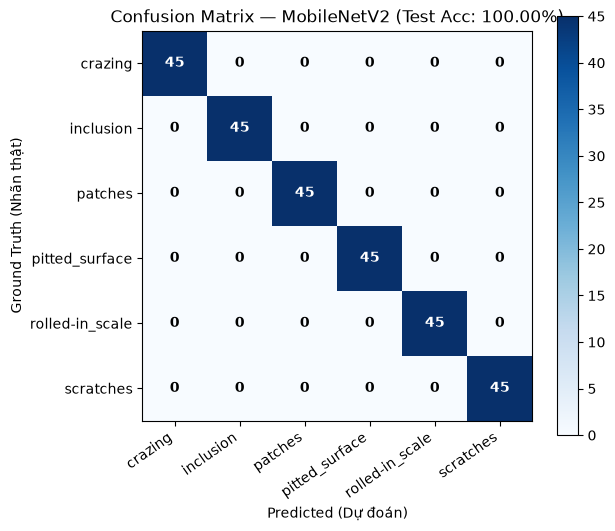

Đã lưu Confusion Matrix tại: /home/nvbao/Projects/industrial-defect/assets/confusion_matrix_neu.png


In [17]:
# Load lại trọng số tốt nhất để đánh giá trên tập Test độc lập
model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
test_loss, test_acc, y_true, y_pred = run_epoch(test_loader, is_train=False)

print(f"TEST ACCURACY: {test_acc*100:.2f}% (Loss: {test_loss:.4f})\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

# Vẽ và lưu Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)
ax.set(
    xticks=np.arange(len(CLASS_NAMES)),
    yticks=np.arange(len(CLASS_NAMES)),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    ylabel="Ground Truth (Nhãn thật)",
    xlabel="Predicted (Dự đoán)",
    title=f"Confusion Matrix — MobileNetV2 (Test Acc: {test_acc*100:.2f}%)",
)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black", fontweight="bold")

plt.tight_layout()
cm_path = ASSETS_DIR / "confusion_matrix_neu.png"
plt.savefig(cm_path, dpi=150)
plt.show()
print(f"Đã lưu Confusion Matrix tại: {cm_path}")

## 5. Phẫu thuật đồ thị ONNX (Graph Surgery và BatchNorm Folding)

### 5.1. Kiểm chứng toán học của BatchNorm Folding bằng NumPy thuần
Ở chế độ suy luận (`eval`), lớp `BatchNorm2d` chỉ thực hiện các phép nhân và cộng tuyến tính theo từng kênh. Vì vậy, ta có thể gộp trực tiếp các tham số $(\gamma, \beta, \mu, \sigma^2, \epsilon)$ vào trọng số $(W, b)$ của lớp `Conv2d` đứng liền trước theo công thức:
$$W_{\text{fold}} = \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} \cdot W, \qquad b_{\text{fold}} = \frac{\gamma}{\sqrt{\sigma^2 + \epsilon}} \cdot (b - \mu) + \beta$$

Đoạn mã dưới đây trích xuất cặp lớp đầu tiên (`features[0][0]: Conv2d` và `features[0][1]: BatchNorm2d`) từ mô hình `MobileNetV2` vừa huấn luyện, thực hiện gập trọng số bằng NumPy và kiểm chứng sai số nằm trong ngưỡng cho phép của `FP32`.

In [24]:
model_cpu = build_mobilenetv2(num_classes=len(CLASS_NAMES), pretrained=False).eval()
model_cpu.load_state_dict(torch.load(model_path, map_location="cpu", weights_only=True))
# Lấy cặp Conv2d + BatchNorm2d đầu tiên của MobileNetV2: features[0][0] và features[0][1]
conv_layer = model_cpu.features[0][0]
bn_layer   = model_cpu.features[0][1]

# 1. Trích xuất trọng số ra NumPy
W = conv_layer.weight.detach().numpy()                         # shape: (C_out, C_in, K, K)
b = conv_layer.bias.detach().numpy() if conv_layer.bias is not None else np.zeros(W.shape[0], dtype=np.float32)
gamma = bn_layer.weight.detach().numpy()                       # shape: (C_out,)
beta  = bn_layer.bias.detach().numpy()                         # shape: (C_out,)
mean  = bn_layer.running_mean.detach().numpy()                 # shape: (C_out,)
var   = bn_layer.running_var.detach().numpy()                  # shape: (C_out,)
eps   = bn_layer.eps

In [26]:
# 2. Áp dụng công thức BatchNorm Folding bằng NumPy
scale = gamma / np.sqrt(var + eps)                             # shape: (C_out,)
W_fold = W * scale.reshape(-1, 1, 1, 1)                        # Broadcast nhân theo trục C_out
b_fold = (b - mean) * scale + beta

# 3. Tạo 1 lớp Conv2d mới duy nhất (có bias=True) chứa trọng số đã gập
fused_conv = nn.Conv2d(
    in_channels=conv_layer.in_channels,
    out_channels=conv_layer.out_channels,
    kernel_size=conv_layer.kernel_size,
    stride=conv_layer.stride,
    padding=conv_layer.padding,
    groups=conv_layer.groups,
    bias=True,
).eval()
with torch.no_grad():
    fused_conv.weight.copy_(torch.from_numpy(W_fold))
    fused_conv.bias.copy_(torch.from_numpy(b_fold))
    # 4. So sánh đầu ra: (Conv -> BN) tách rời vs. Fused Conv duy nhất
    test_x = torch.randn(1, 3, 224, 224)
    y_separate = bn_layer(conv_layer(test_x))
    y_fused    = fused_conv(test_x)
max_diff = (y_separate - y_fused).abs().max().item()
mean_diff = (y_separate - y_fused).abs().mean().item()
print(f"Max absolute difference : {max_diff:.2e}")
print(f"Mean absolute difference: {mean_diff:.2e}")
assert torch.allclose(y_separate, y_fused, rtol=1e-4, atol=1e-5), "Sai số vượt ngưỡng FP32!"
print("Kiểm chứng công thức BatchNorm Folding thành công!")

Max absolute difference : 1.53e-05
Mean absolute difference: 1.16e-07
Kiểm chứng công thức BatchNorm Folding thành công!


### 5.2. Xuất đồ thị ONNX và tối ưu hóa bằng `onnx-simplifier`
- Xuất file `models/model_unfolded.onnx` (với cờ `TrainingMode.PRESERVE`) để giữ nguyên các node `BatchNormalization`, phục vụ việc trực quan hóa cấu trúc đồ thị trước tối ưu trên Netron.
- Xuất file `models/model_raw.onnx` ở chế độ `eval` chuẩn (`opset_version=17`, hỗ trợ `dynamic_axes` cho kích thước batch).
- Chạy `onnxsim.simplify()` để thực hiện constant folding, shape inference và loại bỏ các node dư thừa, xuất ra file tối ưu `models/model_opt.onnx`.
- So sánh bảng thống kê số lượng từng loại toán tử (`Conv`, `BatchNormalization`, `Clip`, `Add`, `Gemm`) trước và sau khi tối ưu.

In [27]:
from collections import Counter
import onnx
from onnxsim import simplify

dummy_input = torch.randn(1, 3, 224, 224)
unfolded_onnx_path = MODELS_DIR / "model_unfolded.onnx"
raw_onnx_path      = MODELS_DIR / "model_raw.onnx"
opt_onnx_path      = MODELS_DIR / "model_opt.onnx"

# 1. Xuất bản giữ nguyên node BatchNormalization (dùng để chụp ảnh Netron trước tối ưu)
torch.onnx.export(
    model_cpu,
    dummy_input,
    str(unfolded_onnx_path),
    export_params=True,
    opset_version=17,
    do_constant_folding=False,
    training=torch.onnx.TrainingMode.PRESERVE,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}},
    dynamo=False,
)

# 2. Xuất bản chuẩn eval (PyTorch tự gập BatchNorm vào Conv)
torch.onnx.export(
    model_cpu,
    dummy_input,
    str(raw_onnx_path),
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}},
    dynamo=False,
)

# 3. Chạy onnx-simplifier để dọn dẹp đồ thị và gập hằng số triệt để
onnx_model = onnx.load(str(raw_onnx_path))
onnx.checker.check_model(onnx_model)

model_simp, check = simplify(onnx_model)
assert check, "Simplified ONNX model failed validation!"
onnx.save(model_simp, str(opt_onnx_path))

# 4. Đếm số lượng từng loại toán tử (NodeProto.op_type) trong GraphProto
def count_ops(path):
    m = onnx.load(str(path))
    ops = Counter(node.op_type for node in m.graph.node)
    return len(m.graph.node), ops

n_unf, ops_unf = count_ops(unfolded_onnx_path)
n_raw, ops_raw = count_ops(raw_onnx_path)
n_opt, ops_opt = count_ops(opt_onnx_path)

print(f"{'Operator':<22} | {'Unfolded (Before)':>17} | {'Raw (EVAL)':>12} | {'Optimized (onnxsim)':>19}")
print("-" * 78)
all_ops = sorted(set(ops_unf) | set(ops_raw) | set(ops_opt))
for op in all_ops:
    print(f"{op:<22} | {ops_unf.get(op, 0):>17} | {ops_raw.get(op, 0):>12} | {ops_opt.get(op, 0):>19}")
print("-" * 78)
print(f"{'TOTAL NODES':<22} | {n_unf:>17} | {n_raw:>12} | {n_opt:>19}")
print(f"{'FILE SIZE (MB)':<22} | {os.path.getsize(unfolded_onnx_path)/1024**2:>17.2f} | {os.path.getsize(raw_onnx_path)/1024**2:>12.2f} | {os.path.getsize(opt_onnx_path)/1024**2:>19.2f}")

/tmp/ipykernel_26556/4114709776.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/tmp/ipykernel_26556/4114709776.py:26: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Operator               | Unfolded (Before) |   Raw (EVAL) | Optimized (onnxsim)
------------------------------------------------------------------------------
Add                    |                10 |           10 |                  10
BatchNormalization     |                52 |            0 |                   0
Clip                   |                35 |           35 |                  35
Constant               |                70 |           70 |                   2
Conv                   |                52 |           52 |                  52
Flatten                |                 1 |            1 |                   1
Gemm                   |                 1 |            1 |                   1
GlobalAveragePool      |                 1 |            1 |                   1
------------------------------------------------------------------------------
TOTAL NODES            |               222 |          170 |                 102
FILE SIZE (MB)         |              8.71

## 6. Kiểm định sai số số học trên tập kiểm thử (Numerical Validation)

Khi chuyển đổi mô hình từ PyTorch sang ONNX Runtime và gập các lớp BatchNorm, thứ tự các phép toán dấu phẩy động (`FP32`) và tập lệnh SIMD trên CPU có thể thay đổi nhẹ, tạo ra sai số làm tròn tích lũy qua 52 tầng tích chập.

Ta chạy suy luận song song cả hai mô hình (PyTorch gốc và `model_opt.onnx` trên ONNX Runtime) trên toàn bộ 270 ảnh của tập Test độc lập để kiểm chứng:
- Sai số tuyệt đối cực đại trên xác suất Softmax nhỏ hơn $10^{-5}$: $\max(\lvert P_{\text{torch}} - P_{\text{onnx}} \rvert) < 10^{-5}$.
- Độ trùng khớp dự đoán lớp (Top-1 Prediction Agreement) đạt **100%** và độ chính xác không hề bị suy giảm.

In [28]:
import onnxruntime as ort

# Khởi tạo ONNX Runtime session trên CPU với mức tối ưu đồ thị cao nhất
sess_opts = ort.SessionOptions()
sess_opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
ort_session = ort.InferenceSession(
    str(opt_onnx_path),
    sess_options=sess_opts,
    providers=["CPUExecutionProvider"],
)
input_name = ort_session.get_inputs()[0].name

def softmax_np(x):
    e = np.exp(x - np.max(x, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

model_cpu.eval()
all_labels = []
torch_logits_list, onnx_logits_list = [], []

with torch.no_grad():
    for imgs, lbls in test_loader:
        # 1. Suy luận bằng PyTorch CPU
        t_out = model_cpu(imgs).numpy()
        # 2. Suy luận bằng ONNX Runtime CPU
        o_out = ort_session.run(None, {input_name: imgs.numpy()})[0]

        torch_logits_list.append(t_out)
        onnx_logits_list.append(o_out)
        all_labels.append(lbls.numpy())

torch_logits = np.concatenate(torch_logits_list, axis=0)
onnx_logits  = np.concatenate(onnx_logits_list, axis=0)
y_true_test  = np.concatenate(all_labels, axis=0)

torch_probs = softmax_np(torch_logits)
onnx_probs  = softmax_np(onnx_logits)

# Tính sai số tuyệt đối trên cả logits và xác suất Softmax
logit_diff = np.abs(torch_logits - onnx_logits)
prob_diff  = np.abs(torch_probs - onnx_probs)

torch_preds = torch_logits.argmax(axis=1)
onnx_preds  = onnx_logits.argmax(axis=1)

torch_acc = (torch_preds == y_true_test).mean() * 100
onnx_acc  = (onnx_preds == y_true_test).mean() * 100
agreement = (torch_preds == onnx_preds).mean() * 100

print("=== KẾT QUẢ KIỂM ĐỊNH SỐ HỌC TRÊN TẬP TEST (270 ẢNH) ===")
print(f"Logits  -> Max diff: {logit_diff.max():.2e} | Mean diff: {logit_diff.mean():.2e}")
print(f"Softmax -> Max diff: {prob_diff.max():.2e} | Mean diff: {prob_diff.mean():.2e}")
print("-" * 60)
print(f"PyTorch Test Accuracy      : {torch_acc:.2f}%")
print(f"ONNX Runtime Test Accuracy : {onnx_acc:.2f}%")
print(f"Top-1 Prediction Agreement : {agreement:.2f}%")

assert prob_diff.max() < 1e-5, f"Sai số xác suất vượt ngưỡng 1e-5: {prob_diff.max():.2e}"
assert agreement == 100.0, "Dự đoán giữa PyTorch và ONNX Runtime không khớp 100%!"
print("\n✅ Đạt chuẩn kiểm định: Sai số < 1e-5 và giữ nguyên 100% độ chính xác!")

=== KẾT QUẢ KIỂM ĐỊNH SỐ HỌC TRÊN TẬP TEST (270 ẢNH) ===
Logits  -> Max diff: 2.38e-05 | Mean diff: 2.37e-06
Softmax -> Max diff: 4.83e-06 | Mean diff: 6.75e-09
------------------------------------------------------------
PyTorch Test Accuracy      : 100.00%
ONNX Runtime Test Accuracy : 100.00%
Top-1 Prediction Agreement : 100.00%

✅ Đạt chuẩn kiểm định: Sai số < 1e-5 và giữ nguyên 100% độ chính xác!


## 7. Đo hiệu năng suy luận chuẩn sản xuất trên CPU (Production Benchmark)

Để đo độ trễ suy luận một cách khách quan và sát với thực tế dây chuyền công nghiệp (camera chụp từng ảnh một, `batch_size = 1`), ta áp dụng quy trình chuẩn:
- **Khóa số luồng CPU:** Cấu hình đồng nhất số luồng (`1 thread` cho kịch bản đơn nhân biên và `4 threads` cho đa nhân) cho cả PyTorch (`torch.set_num_threads`) và ONNX Runtime (`intra_op_num_threads`, chế độ thực thi tuần tự `ORT_SEQUENTIAL`).
- **Khởi động (warm-up):** Chạy 50 vòng lặp ban đầu để ổn định bộ nhớ đệm CPU (L1/L2/L3 cache) và vùng cấp phát bộ nhớ.
- **Thống kê phân vị độ trễ:** Chạy 500 vòng lặp thực tế để đo **Mean, P50 (trung vị), P95, P99 Latency (ms)** cùng **Throughput (FPS)**. Trong sản xuất, P95 và P99 là hai chỉ số quyết định hệ thống có đảm bảo không bị trễ khung hình hay không.

Engine                   | Thr |  Mean(ms) |  P50(ms) |  P95(ms) |  P99(ms) |     FPS
----------------------------------------------------------------------------------
PyTorch Eager (CPU)      |   1 |     22.07 |    20.05 |    36.11 |    42.29 |    45.3
ONNX Runtime Opt (CPU)   |   1 |      9.78 |     9.00 |    15.31 |    20.83 |   102.3
PyTorch Eager (CPU)      |   4 |     26.55 |    25.05 |    43.90 |    61.06 |    37.7
ONNX Runtime Opt (CPU)   |   4 |      4.71 |     4.35 |     7.07 |    10.40 |   212.5
=> Tốc độ tăng tốc (1 luồng): ONNX Runtime nhanh hơn PyTorch 2.26x
=> Tốc độ tăng tốc (4 luồng): ONNX Runtime nhanh hơn PyTorch 5.64x


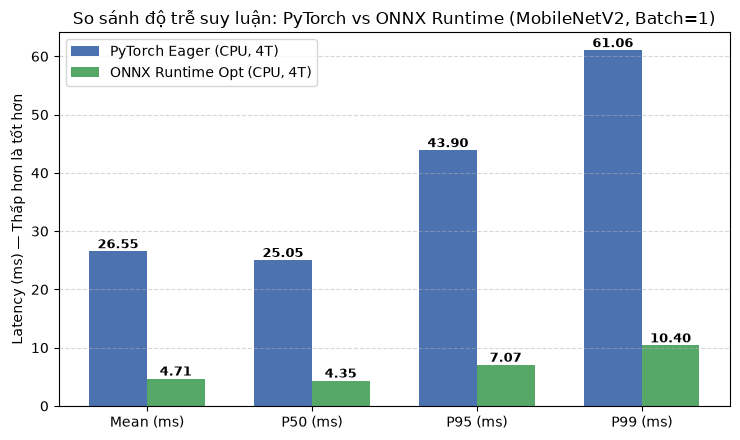

📊 Đã lưu biểu đồ benchmark tại: /home/nvbao/Projects/industrial-defect/assets/benchmark_latency.png


In [29]:
def benchmark_cpu(num_threads: int = 4, warmup: int = 50, runs: int = 500):
    torch.set_num_threads(num_threads)

    opts = ort.SessionOptions()
    opts.intra_op_num_threads = num_threads
    opts.inter_op_num_threads = 1
    opts.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

    session = ort.InferenceSession(
        str(opt_onnx_path),
        sess_options=opts,
        providers=["CPUExecutionProvider"],
    )
    in_name = session.get_inputs()[0].name

    x_torch = torch.randn(1, 3, 224, 224)
    x_numpy = x_torch.numpy()

    # 1. Benchmark PyTorch CPU
    with torch.no_grad():
        for _ in range(warmup):
            _ = model_cpu(x_torch)
        pt_lats = []
        for _ in range(runs):
            t0 = time.perf_counter()
            _ = model_cpu(x_torch)
            pt_lats.append((time.perf_counter() - t0) * 1000.0)

    # 2. Benchmark ONNX Runtime CPU
    for _ in range(warmup):
        _ = session.run(None, {in_name: x_numpy})
    ort_lats = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = session.run(None, {in_name: x_numpy})
        ort_lats.append((time.perf_counter() - t0) * 1000.0)

    def summarize(name, lats):
        arr = np.array(lats)
        return {
            "Engine": name,
            "Threads": num_threads,
            "Mean (ms)": float(arr.mean()),
            "P50 (ms)": float(np.percentile(arr, 50)),
            "P95 (ms)": float(np.percentile(arr, 95)),
            "P99 (ms)": float(np.percentile(arr, 99)),
            "FPS": float(1000.0 / arr.mean()),
        }

    return summarize("PyTorch Eager (CPU)", pt_lats), summarize("ONNX Runtime Opt (CPU)", ort_lats)

bench_rows = []
for n_thr in [1, 4]:
    pt_res, ort_res = benchmark_cpu(num_threads=n_thr, warmup=50, runs=500)
    bench_rows.extend([pt_res, ort_res])

print(f"{'Engine':<24} | {'Thr':>3} | {'Mean(ms)':>9} | {'P50(ms)':>8} | {'P95(ms)':>8} | {'P99(ms)':>8} | {'FPS':>7}")
print("-" * 82)
for r in bench_rows:
    print(f"{r['Engine']:<24} | {r['Threads']:>3} | {r['Mean (ms)']:>9.2f} | {r['P50 (ms)']:>8.2f} | {r['P95 (ms)']:>8.2f} | {r['P99 (ms)']:>8.2f} | {r['FPS']:>7.1f}")

for i in [0, 2]:
    speedup = bench_rows[i]["Mean (ms)"] / bench_rows[i + 1]["Mean (ms)"]
    print(f"=> Tốc độ tăng tốc ({bench_rows[i]['Threads']} luồng): ONNX Runtime nhanh hơn PyTorch {speedup:.2f}x")

# Vẽ biểu đồ so sánh độ trễ (4 luồng CPU)
pt_4, ort_4 = bench_rows[2], bench_rows[3]
metrics = ["Mean (ms)", "P50 (ms)", "P95 (ms)", "P99 (ms)"]
pt_vals  = [pt_4[m] for m in metrics]
ort_vals = [ort_4[m] for m in metrics]

x_pos = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(7.5, 4.5))
b1 = ax.bar(x_pos - width/2, pt_vals,  width, label="PyTorch Eager (CPU, 4T)", color="#4c72b0")
b2 = ax.bar(x_pos + width/2, ort_vals, width, label="ONNX Runtime Opt (CPU, 4T)", color="#55a868")

for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.2f}", (bar.get_x() + bar.get_width()/2, h),
                    ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylabel("Latency (ms) — Thấp hơn là tốt hơn")
ax.set_title("So sánh độ trễ suy luận: PyTorch vs ONNX Runtime (MobileNetV2, Batch=1)")
ax.set_xticks(x_pos)
ax.set_xticklabels(metrics)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
bench_img = ASSETS_DIR / "benchmark_latency.png"
plt.savefig(bench_img, dpi=150)
plt.show()
print(f"📊 Đã lưu biểu đồ benchmark tại: {bench_img}")

## 8. So sánh đối chiếu đa kiến trúc trên NEU Surface Defect (ResNet-18 vs MobileNetV2 vs MobileViT-S)

Để chứng minh quyết định lựa chọn kiến trúc dựa trên số liệu thực nghiệm đầy đủ (Accuracy vs. Efficiency Trade-off), ta huấn luyện thêm `ResNet-18` (CNN truyền thống) và `MobileViT-S` (Hybrid CNN-Transformer) trên cùng bộ chia dữ liệu (`seed=42`), sau đó xuất ONNX và so sánh đồng thời:
- Độ chính xác trên tập Test độc lập (`Test Accuracy`).
- Dung lượng file ONNX (MB).
- Độ trễ suy luận thực tế trên CPU (`ONNX Runtime, 4 threads, Batch=1`).

In [30]:
import timm

def build_model_by_name(name: str, num_classes: int = 6):
    if name == "ResNet-18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m
    elif name == "MobileNetV2":
        return build_mobilenetv2(num_classes=num_classes, pretrained=True)
    elif name == "MobileViT-S":
        return timm.create_model("mobilevit_s", pretrained=True, num_classes=num_classes)
    raise ValueError(name)

def train_eval_and_export(name: str, epochs: int = 10, lr: float = 3e-4):
    print(f"\n🚀 Đang xử lý mô hình: {name} ...")
    set_seed(SEED)
    m = build_model_by_name(name, len(CLASS_NAMES)).to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    pth_file = MODELS_DIR / f"{name.lower().replace('-', '_')}_neu.pth"
    onnx_file = MODELS_DIR / f"{name.lower().replace('-', '_')}_opt.onnx"

    # Nếu MobileNetV2 đã train sẵn ở mục 3 thì nạp luôn cho nhanh
    if name == "MobileNetV2" and model_path.exists():
        m.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
        onnx_file = opt_onnx_path
    else:
        best_acc = 0.0
        for ep in range(1, epochs + 1):
            m.train()
            for imgs, lbls in train_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                opt.zero_grad()
                loss = crit(m(imgs), lbls)
                loss.backward()
                opt.step()
            sched.step()

            m.eval()
            correct, total = 0, 0
            with torch.no_grad():
                for imgs, lbls in val_loader:
                    imgs, lbls = imgs.to(device), lbls.to(device)
                    correct += (m(imgs).argmax(1) == lbls).sum().item()
                    total += lbls.size(0)
            va_acc = correct / total
            if va_acc >= best_acc:
                best_acc = va_acc
                torch.save(m.state_dict(), pth_file)
        m.load_state_dict(torch.load(pth_file, map_location=device, weights_only=True))

        # Xuất ONNX
        m_cpu = m.cpu().eval()
        torch.onnx.export(
            m_cpu, torch.randn(1, 3, 224, 224), str(onnx_file),
            export_params=True, opset_version=17, do_constant_folding=True,
            input_names=["input"], output_names=["logits"],
            dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}},
            dynamo=False,
        )

    # Đánh giá trên tập Test (270 ảnh)
    m = m.to(device).eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, lbls in test_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            correct += (m(imgs).argmax(1) == lbls).sum().item()
            total += lbls.size(0)
    test_acc = correct / total * 100

    # Benchmark ONNX Runtime CPU (4 threads, 30 warm-up + 200 runs)
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = 4
    opts.inter_op_num_threads = 1
    opts.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    sess = ort.InferenceSession(str(onnx_file), sess_options=opts, providers=["CPUExecutionProvider"])
    in_name = sess.get_inputs()[0].name
    x_np = np.random.randn(1, 3, 224, 224).astype(np.float32)

    for _ in range(30):
        _ = sess.run(None, {in_name: x_np})
    lats = []
    for _ in range(200):
        t0 = time.perf_counter()
        _ = sess.run(None, {in_name: x_np})
        lats.append((time.perf_counter() - t0) * 1000.0)

    arr = np.array(lats)
    return {
        "Model": name,
        "Test Acc (%)": test_acc,
        "ONNX Size (MB)": os.path.getsize(onnx_file) / (1024 ** 2),
        "ORT Mean (ms)": float(arr.mean()),
        "ORT P95 (ms)": float(np.percentile(arr, 95)),
        "ORT FPS": float(1000.0 / arr.mean()),
    }

comparison = [train_eval_and_export(name, epochs=10) for name in ["ResNet-18", "MobileNetV2", "MobileViT-S"]]

print("\n=== BẢNG TỔNG HỢP SO SÁNH 3 KIẾN TRÚC TRÊN NEU SURFACE DEFECT ===")
print(f"{'Model':<16} | {'Test Acc(%)':>11} | {'ONNX(MB)':>9} | {'ORT Mean(ms)':>12} | {'ORT P95(ms)':>11} | {'ORT FPS':>8}")
print("-" * 80)
for r in comparison:
    print(f"{r['Model']:<16} | {r['Test Acc (%)']:>11.2f} | {r['ONNX Size (MB)']:>9.2f} | {r['ORT Mean (ms)']:>12.2f} | {r['ORT P95 (ms)']:>11.2f} | {r['ORT FPS']:>8.1f}")

/home/nvbao/miniconda3/envs/cvision/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



🚀 Đang xử lý mô hình: ResNet-18 ...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/nvbao/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 27.0MB/s]
/tmp/ipykernel_26556/1515056461.py:56: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(



🚀 Đang xử lý mô hình: MobileNetV2 ...

🚀 Đang xử lý mô hình: MobileViT-S ...


/home/nvbao/miniconda3/envs/cvision/lib/python3.11/site-packages/timm/models/mobilevit.py:248: TracerWarning: Converting a tensor to a Python float might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  new_h, new_w = math.ceil(H / patch_h) * patch_h, math.ceil(W / patch_w) * patch_w
/home/nvbao/miniconda3/envs/cvision/lib/python3.11/site-packages/timm/models/mobilevit.py:252: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if new_h != H or new_w != W:



=== BẢNG TỔNG HỢP SO SÁNH 3 KIẾN TRÚC TRÊN NEU SURFACE DEFECT ===
Model            | Test Acc(%) |  ONNX(MB) | ORT Mean(ms) | ORT P95(ms) |  ORT FPS
--------------------------------------------------------------------------------
ResNet-18        |      100.00 |     42.64 |        15.52 |       19.86 |     64.4
MobileNetV2      |      100.00 |      8.49 |         4.07 |        5.29 |    245.5
MobileViT-S      |      100.00 |     19.03 |        43.94 |       57.86 |     22.8
